In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Lasso, Ridge
from sklearn.metrics import mean_squared_error, r2_score

In [2]:
data = {
    'X': [1, 2, 3, 4, 5, 6, 7, 8, 9],
    'Y': [5, 7, 9, 11, 13, 15, 17, 19, 21]
}

df = pd.DataFrame(data)

print(df)

   X   Y
0  1   5
1  2   7
2  3   9
3  4  11
4  5  13
5  6  15
6  7  17
7  8  19
8  9  21


In [3]:
X = df[['X']]
y = df['Y']

In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [5]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

In [6]:
lasso_model = Lasso(alpha=0.1)

lasso_model.fit(X_train_scaled, y_train)

lasso_predictions = lasso_model.predict(X_test_scaled)

print("Lasso Regression")
print("--------------------")

print("Coefficient:", lasso_model.coef_)
print("Intercept:", lasso_model.intercept_)

print("Predicted Values:", lasso_predictions)
print("Actual Values:", y_test.values)

print("Mean Squared Error:",
      mean_squared_error(y_test, lasso_predictions))

print("R2 Score:",
      r2_score(y_test, lasso_predictions))

Lasso Regression
--------------------
Coefficient: [4.79897949]
Intercept: 13.0
Predicted Values: [18.87752551  7.12247449]
Actual Values: [19  7]
Mean Squared Error: 0.01500000000000051
R2 Score: 0.9995833333333333


In [7]:
ridge_model = Ridge(alpha=0.1)

ridge_model.fit(X_train_scaled, y_train)

ridge_predictions = ridge_model.predict(X_test_scaled)

print("Ridge Regression")
print("--------------------")

print("Coefficient:", ridge_model.coef_)
print("Intercept:", ridge_model.intercept_)

print("Predicted Values:", ridge_predictions)
print("Actual Values:", y_test.values)

print("Mean Squared Error:",
      mean_squared_error(y_test, ridge_predictions))

print("R2 Score:",
      r2_score(y_test, ridge_predictions))

Ridge Regression
--------------------
Coefficient: [4.82997977]
Intercept: 13.0
Predicted Values: [18.91549296  7.08450704]
Actual Values: [19  7]
Mean Squared Error: 0.007141440190438386
R2 Score: 0.9998016266613767


In [8]:
results = pd.DataFrame({
    'Model': ['Lasso Regression', 'Ridge Regression'],
    'MSE': [
        mean_squared_error(y_test, lasso_predictions),
        mean_squared_error(y_test, ridge_predictions)
    ],
    'R2 Score': [
        r2_score(y_test, lasso_predictions),
        r2_score(y_test, ridge_predictions)
    ]
})

print(results)

              Model       MSE  R2 Score
0  Lasso Regression  0.015000  0.999583
1  Ridge Regression  0.007141  0.999802


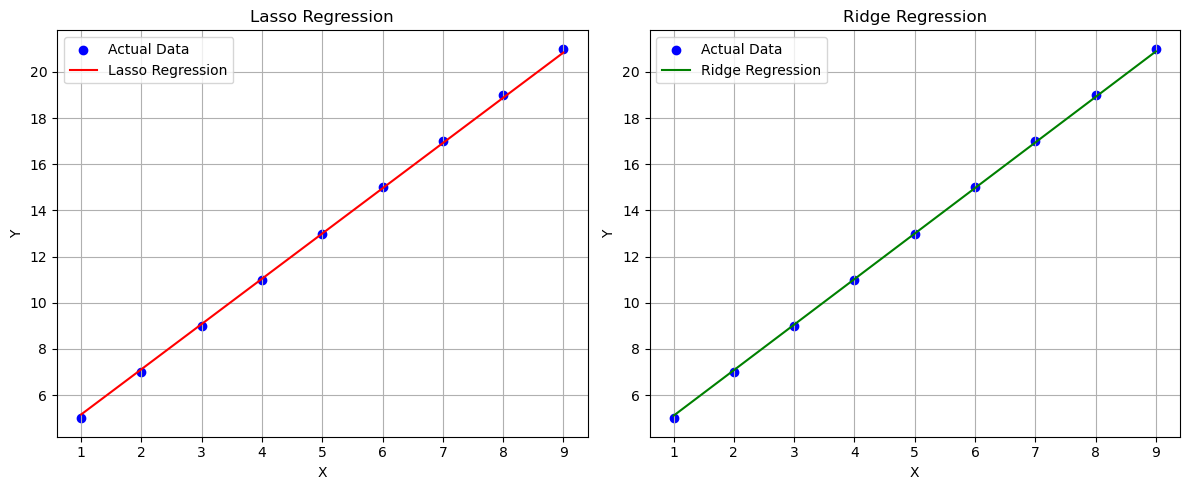

In [9]:
plt.figure(figsize=(12, 5))

# Lasso Regression
plt.subplot(1, 2, 1)

plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(
    X,
    lasso_model.predict(scaler.transform(X)),
    color='red',
    label='Lasso Regression'
)

plt.title('Lasso Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)


# Ridge Regression
plt.subplot(1, 2, 2)

plt.scatter(X, y, color='blue', label='Actual Data')

plt.plot(
    X,
    ridge_model.predict(scaler.transform(X)),
    color='green',
    label='Ridge Regression'
)

plt.title('Ridge Regression')
plt.xlabel('X')
plt.ylabel('Y')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()